PIPELINE DETEKSI JALUR JALAN - HSV + CONTOUR
Optimized untuk Lajur Kiri (Indonesia)

MEMULAI PIPELINE DETEKSI JALAN

[INFO] Gambar berhasil dimuat: lurus.png

------------------------------------------------------------
CONFIGURASI PARAMETER HSV
------------------------------------------------------------
  v_min: 50
  v_max: 255
  s_max: 100
  ROI Points: [(450, 1010), (1410, 1010), (970, 635), (970, 635)]
------------------------------------------------------------


TAHAP 1: ORIGINAL IMAGE


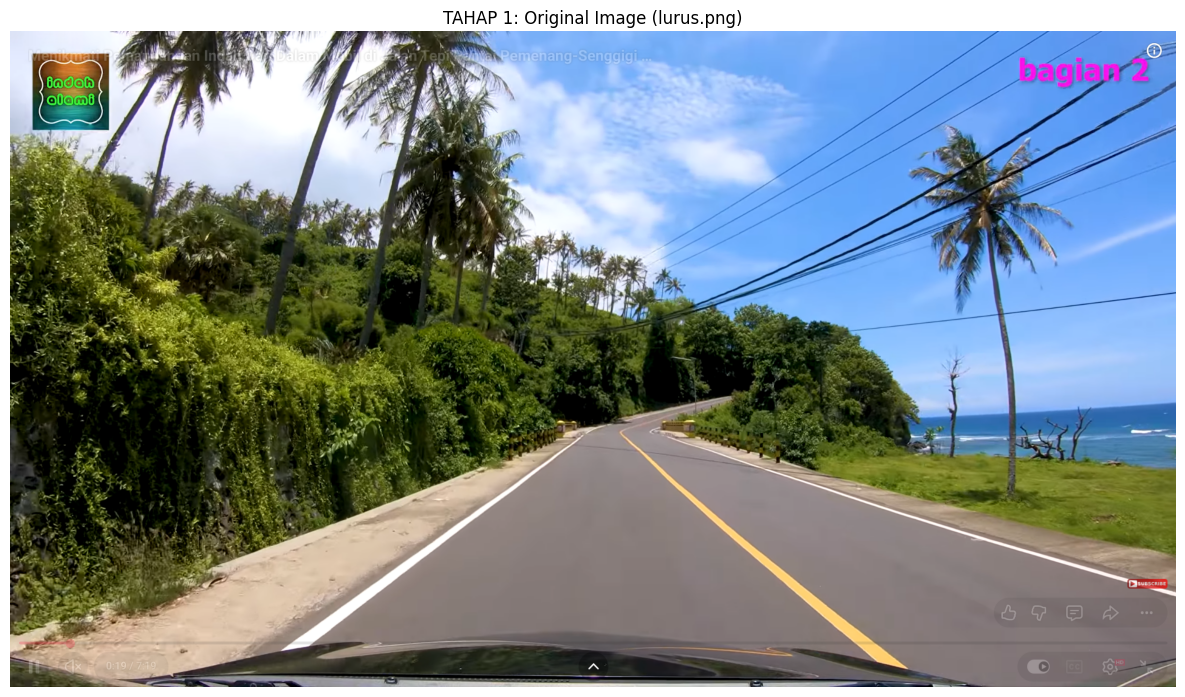

[INFO] Dimensi gambar: (1080, 1920, 3)
[INFO] Tipe data: uint8

TAHAP 2: PREPROCESSING (Blur + HSV)


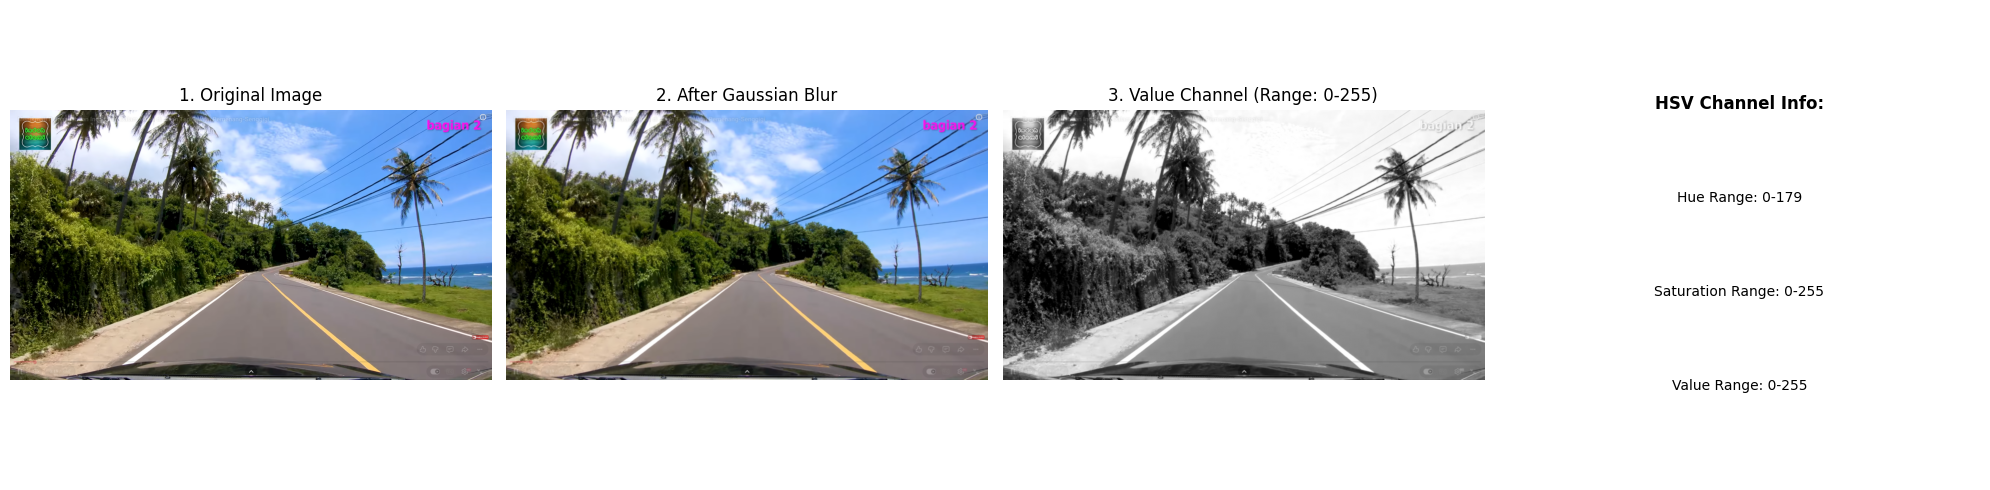

[INFO] Value Channel Range: 0 - 255

TAHAP 3: REGION OF INTEREST (ROI)


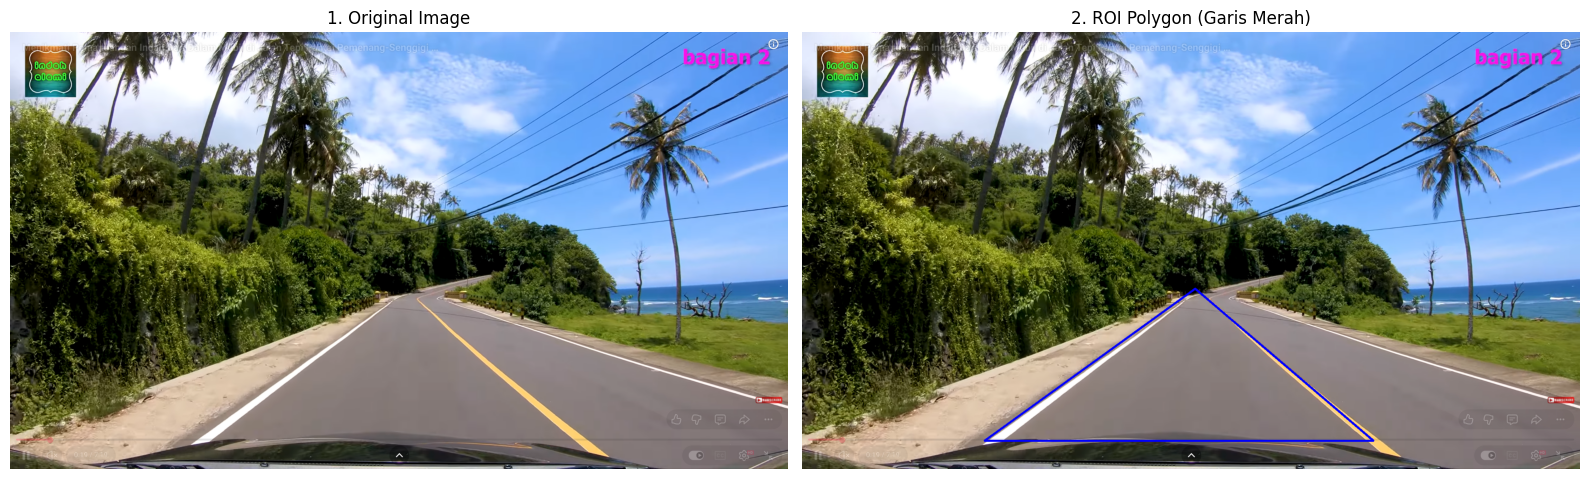

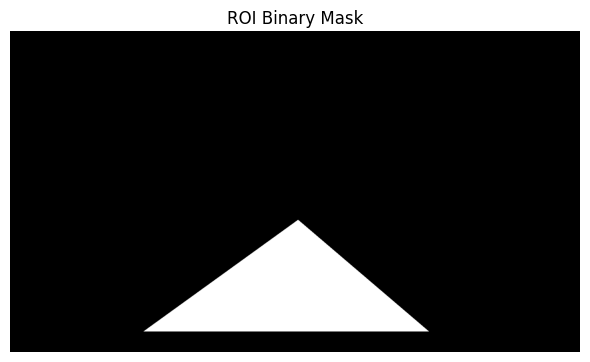

[INFO] Persentase area ROI: 8.73%
[INFO] ROI Points: [(450, 1010), (1410, 1010), (970, 635), (970, 635)]

TAHAP 4: HSV THRESHOLDING (KRITIS)


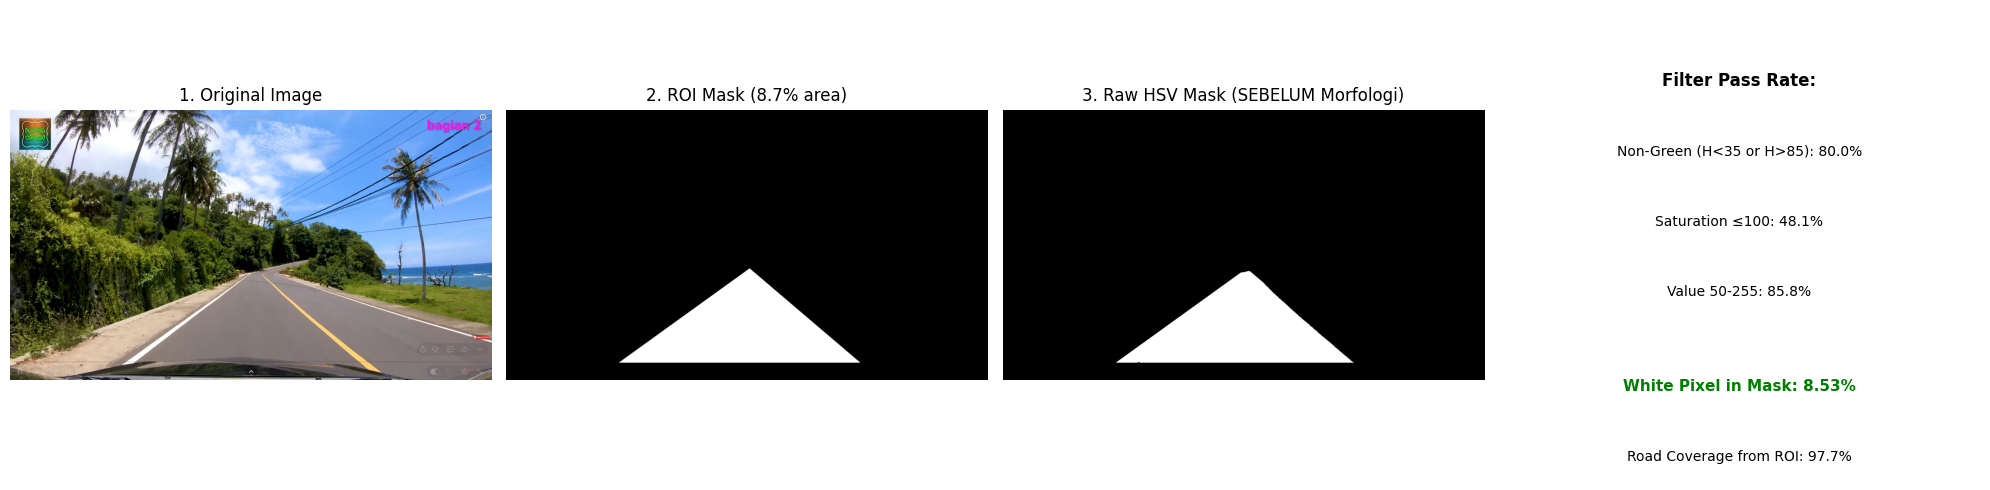


[ANALISIS] Persentase piksel putih di mask: 8.53%
[ANALISIS] Coverage jalan dari ROI: 97.7%
[WARNING] ⚠️ Coverage terlalu tinggi! Mungkin mendeteksi trotoar/lajur lawan.

TAHAP 5: MORPHOLOGICAL OPERATIONS


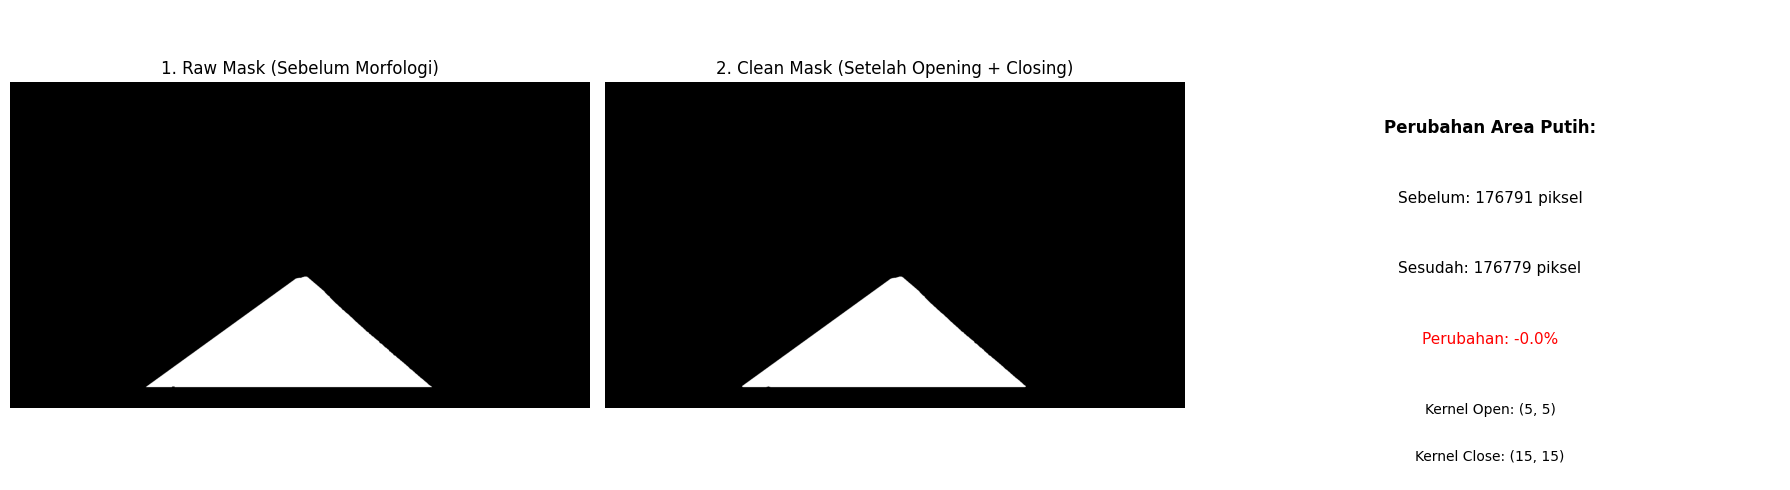

[INFO] Kernel Opening: (5, 5)
[INFO] Kernel Closing: (15, 15)

TAHAP 6: CONTOUR DETECTION


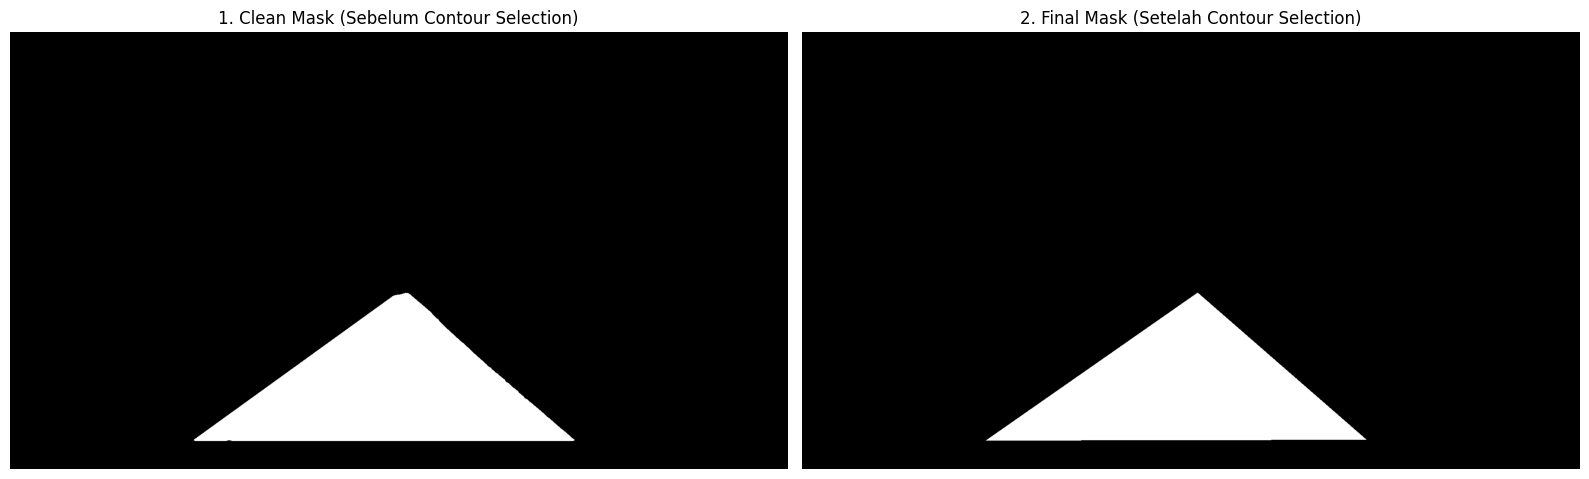

[INFO] ✅ Kontur berhasil ditemukan!
[INFO] Jumlah titik kontur: 3
[INFO] Area kontur: 170194.00 piksel

TAHAP 7: FINAL OVERLAY RESULT


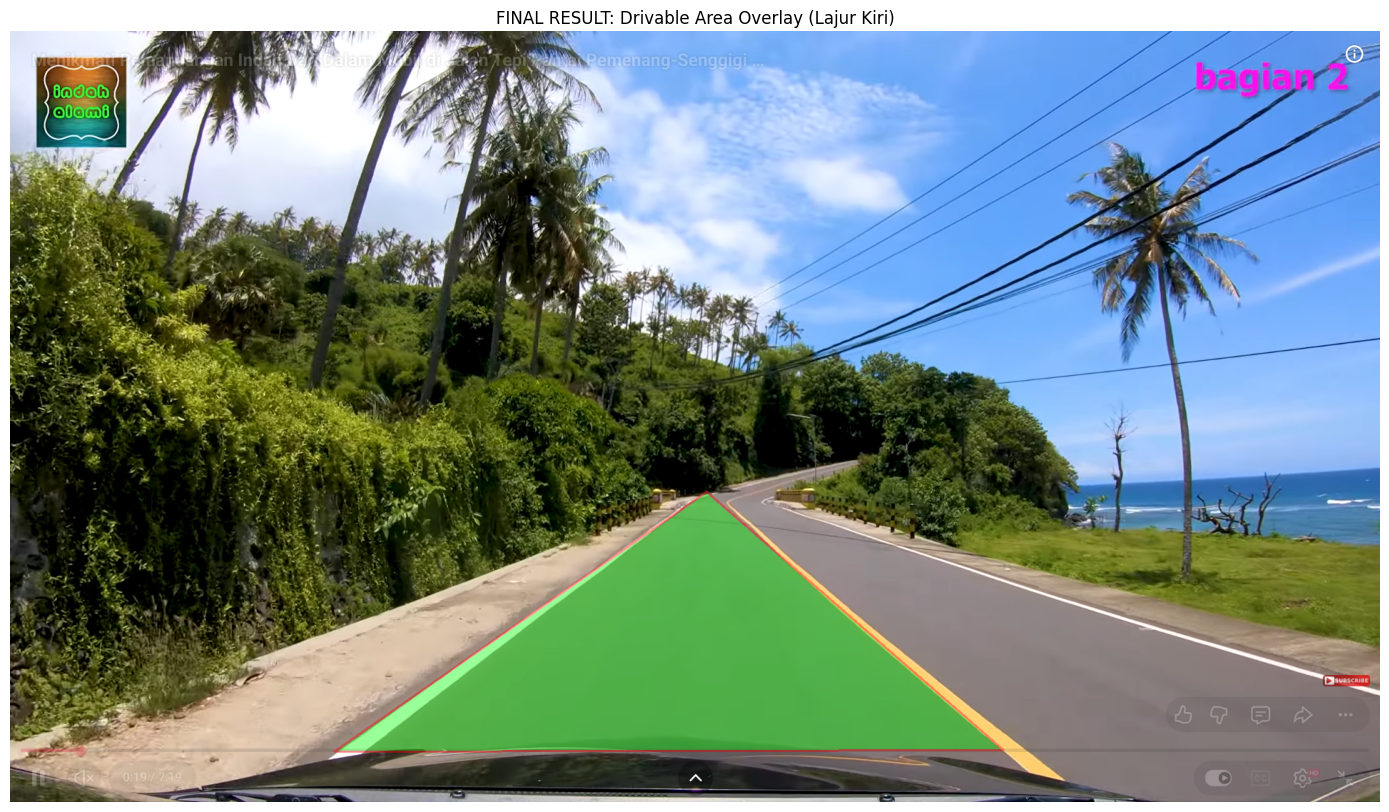

[INFO] Hasil visualisasi selesai!

[INFO] Hasil overlay berhasil disimpan sebagai: 'result_lurus.png'

PIPELINE SELESAI



In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("=" * 60)
print("PIPELINE DETEKSI JALUR JALAN - HSV + CONTOUR")
print("Optimized untuk Lajur Kiri (Indonesia)")
print("=" * 60)

# ==========================================
# CLASS DEFINITION
# ==========================================

class RoadLaneDetectorHSV:
    """
    Class untuk deteksi area jalur jalan (Drivable Area Lajur Kiri - Indonesia)
    menggunakan HSV Color Segmentation + Polygonal ROI + Morphological Filtering + Contour Detection.


    """

    def __init__(self, config=None):
        # Konfigurasi parameter default
        if config is None:
            self.config = {
                'blur_kernel': (5, 5),
                'blur_sigma': 1.2,

                # ==========================================
                # ROI - 4 TITIK MANUAL
                # ==========================================
                'roi_points': [
                    (450, 1010),    # Titik 1: Kiri Bawah
                    (1410, 1010),   # Titik 2: Kanan Bawah
                    (970, 635),    # Titik 3: Kanan Atas
                    (970, 635)     # Titik 4: Kiri Atas
                ],

                'h_reject_green': (35, 85),      # Rentang Hue hijau yang dieliminasi
                's_max': 100,                    # ✅ DIPERBAIKI: 90 → 100 (aspal terang masih lolos)
                'v_min': 50,                     # ✅ DIPERBAIKI: 40 → 50 (buang trotoar terang)
                'v_max': 255,                    # ✅ DIPERBAIKI: 210 → 255 (terima semua piksel terang)
                'kernel_open_size': (5, 5),      # Kernel untuk operasi Opening
                'kernel_close_size': (15, 15),   # Kernel untuk operasi Closing
                'min_contour_area': 1000,        # Area kontur minimal (piksel)
                'dp_epsilon_ratio': 0.01         # Rasio presisi Douglas-Peucker
            }
        else:
            self.config = config

    def apply_roi(self, image):
        """
        Membuat ROI Poligonal berdasarkan 4 titik koordinat manual
        untuk memfokuskan deteksi hanya pada lajur kiri
        (sesuai aturan kemudi Indonesia).

        ROI menggunakan 4 titik:
        1. Kiri Bawah
        2. Kanan Bawah
        3. Kanan Atas
        4. Kiri Atas
        """

        h, w = image.shape[:2]

        # Mengambil 4 titik ROI dari konfigurasi
        roi_points = self.config['roi_points']

        # Membentuk polygon ROI
        roi_corners = np.array([roi_points], dtype=np.int32)

        # Buat ROI Mask biner
        roi_mask = np.zeros((h, w), dtype=np.uint8)
        cv2.fillPoly(roi_mask, roi_corners, 255)

        # Visualisasi bentuk ROI Poligonal
        roi_visual = image.copy()
        cv2.polylines(
            roi_visual,
            roi_corners,
            isClosed=True,
            color=(255, 0, 0),
            thickness=3
        )

        return roi_mask, roi_visual, roi_corners

    def create_hsv_mask(self, hsv_img, roi_mask):
        """Membentuk mask biner berdasarkan kriteria warna HSV di dalam area ROI."""
        H = hsv_img[:, :, 0]
        S = hsv_img[:, :, 1]
        V = hsv_img[:, :, 2]

        # 1. Eksklusi warna vegetasi (Hijau)
        green_low, green_high = self.config['h_reject_green']
        non_green_mask = (H < green_low) | (H > green_high)

        # 2. Filter Saturation & Value (Aspal & Marka Jalan)
        s_mask = S <= self.config['s_max']
        v_mask = (V >= self.config['v_min']) & (V <= self.config['v_max'])

        # Kombinasi kriteria warna dengan kondisi ROI
        binary_mask = np.logical_and.reduce((non_green_mask, s_mask, v_mask, roi_mask > 0))
        return (binary_mask * 255).astype(np.uint8)

    def apply_morphology(self, mask):
        """Pembersihan noise dan pengisian lubang menggunakan operasi morfologi."""
        kernel_open = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            self.config['kernel_open_size']
        )

        kernel_close = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            self.config['kernel_close_size']
        )

        # Opening: Menghilangkan noise kecil/bintik piksel
        opened_mask = cv2.morphologyEx(
            mask,
            cv2.MORPH_OPEN,
            kernel_open
        )

        # Closing: Menutup lubang/bayangan kecil pada aspal
        closed_mask = cv2.morphologyEx(
            opened_mask,
            cv2.MORPH_CLOSE,
            kernel_close
        )

        return closed_mask

    def extract_drivable_contour(self, mask):
        """Mencari dan menyederhanakan kontur area lajur jalan utama."""
        contours, _ = cv2.findContours(
            mask,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        if not contours:
            return None, None, mask

        # Filter berdasarkan luas minimum dan pilih kontur terbesar
        valid_contours = [
            c for c in contours
            if cv2.contourArea(c) >= self.config['min_contour_area']
        ]

        if not valid_contours:
            return None, None, mask

        largest_contour = max(
            valid_contours,
            key=cv2.contourArea
        )

        # Simplifikasi kontur menggunakan algoritma Douglas-Peucker
        perimeter = cv2.arcLength(
            largest_contour,
            True
        )

        epsilon = self.config['dp_epsilon_ratio'] * perimeter

        approx_contour = cv2.approxPolyDP(
            largest_contour,
            epsilon,
            True
        )

        # Rekonstruksi mask bersih berdasarkan kontur terpilih
        clean_mask = np.zeros_like(mask)

        cv2.drawContours(
            clean_mask,
            [approx_contour],
            -1,
            255,
            thickness=cv2.FILLED
        )

        # Ekstraksi titik koordinat [(x, y), ...]
        steering_points = approx_contour.reshape(-1, 2)

        return approx_contour, steering_points, clean_mask

    def create_overlay(self, original_img, contour):
        """Membuat visualisasi overlay transparan di atas citra asli."""
        overlay = original_img.copy()

        if contour is not None:
            # Mewarnai area jalan dengan warna Hijau Transparan
            cv2.drawContours(
                overlay,
                [contour],
                -1,
                (0, 255, 0),
                thickness=cv2.FILLED
            )

            # Menarik garis tepi kontur dengan warna Merah
            cv2.drawContours(
                overlay,
                [contour],
                -1,
                (0, 0, 255),
                thickness=2
            )

        # Blending citra asli dengan overlay (Alpha = 0.6, Beta = 0.4)
        result = cv2.addWeighted(
            original_img,
            0.6,
            overlay,
            0.4,
            0
        )

        return result

    def calculate_iou(self, predicted_mask, ground_truth_mask):
        """Menghitung metrik Intersection over Union (IoU)."""
        intersection = np.logical_and(
            predicted_mask > 0,
            ground_truth_mask > 0
        ).sum()

        union = np.logical_or(
            predicted_mask > 0,
            ground_truth_mask > 0
        ).sum()

        if union == 0:
            return 0.0

        return float(intersection / union)

    def process_frame(self, image_bgr):
        """Pipeline eksekusi lengkap untuk satu frame citra."""

        # 1. Preprocessing & ROI Poligonal
        blurred = cv2.GaussianBlur(
            image_bgr,
            self.config['blur_kernel'],
            self.config['blur_sigma']
        )

        hsv_img = cv2.cvtColor(
            blurred,
            cv2.COLOR_BGR2HSV
        )

        roi_mask, roi_visual, roi_corners = self.apply_roi(
            image_bgr
        )

        # 2. Thresholding & Morfologi
        raw_mask = self.create_hsv_mask(
            hsv_img,
            roi_mask
        )

        clean_mask = self.apply_morphology(
            raw_mask
        )

        # 3. Deteksi Kontur
        contour, points, final_mask = self.extract_drivable_contour(
            clean_mask
        )

        # 4. Generasi Overlay Transparan
        overlay_img = self.create_overlay(
            image_bgr,
            contour
        )

        return {
            'blurred': blurred,
            'hsv_img': hsv_img,
            'roi_mask': roi_mask,
            'roi_visual': roi_visual,
            'roi_corners': roi_corners,
            'raw_mask': raw_mask,
            'clean_mask': clean_mask,
            'final_mask': final_mask,
            'overlay': overlay_img,
            'points': points,
            'contour': contour
        }


# ==========================================
# FUNGSI VISUALISASI PER TAHAPAN
# ==========================================

def visualize_stage_1_original(img_rgb, file_path):
    """Tahap 1: Tampilkan gambar asli"""
    plt.figure(figsize=(12, 7))

    plt.imshow(img_rgb)
    plt.title(f"TAHAP 1: Original Image ({file_path})")
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    print(f"[INFO] Dimensi gambar: {img_rgb.shape}")
    print(f"[INFO] Tipe data: {img_rgb.dtype}")


def visualize_stage_2_preprocessing(img_rgb, blurred_rgb, hsv_img):
    """Tahap 2: Preprocessing (Blur + HSV Conversion)"""
    h, s, v = cv2.split(hsv_img)

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5)
    )

    axes[0].imshow(img_rgb)
    axes[0].set_title("1. Original Image")
    axes[0].axis('off')

    axes[1].imshow(blurred_rgb)
    axes[1].set_title("2. After Gaussian Blur")
    axes[1].axis('off')

    axes[2].imshow(v, cmap='gray')
    axes[2].set_title(
        f"3. Value Channel (Range: {v.min()}-{v.max()})"
    )
    axes[2].axis('off')

    axes[3].axis('off')

    axes[3].text(
        0.5,
        0.8,
        "HSV Channel Info:",
        ha='center',
        va='center',
        fontsize=12,
        fontweight='bold'
    )

    axes[3].text(
        0.5,
        0.6,
        f"Hue Range: 0-179",
        ha='center',
        va='center',
        fontsize=10
    )

    axes[3].text(
        0.5,
        0.4,
        f"Saturation Range: 0-255",
        ha='center',
        va='center',
        fontsize=10
    )

    axes[3].text(
        0.5,
        0.2,
        f"Value Range: {v.min()}-{v.max()}",
        ha='center',
        va='center',
        fontsize=10
    )

    plt.tight_layout()
    plt.show()

    print(f"[INFO] Value Channel Range: {v.min()} - {v.max()}")


def visualize_stage_3_roi(
    img_rgb,
    roi_visual_rgb,
    roi_mask,
    roi_corners,
    config
):
    """Tahap 3: Region of Interest (ROI)"""
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 6)
    )

    axes[0].imshow(img_rgb)
    axes[0].set_title("1. Original Image")
    axes[0].axis('off')

    axes[1].imshow(roi_visual_rgb)
    axes[1].set_title("2. ROI Polygon (Garis Merah)")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

    # Tampilkan ROI mask terpisah
    plt.figure(figsize=(6, 6))
    plt.imshow(roi_mask, cmap='gray')
    plt.title("ROI Binary Mask")
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    roi_percent = (
        (roi_mask > 0).sum()
        / roi_mask.size
        * 100
    )

    print(f"[INFO] Persentase area ROI: {roi_percent:.2f}%")
    print(f"[INFO] ROI Points: {config['roi_points']}")


def visualize_stage_4_hsv_threshold(
    img_rgb,
    roi_mask,
    raw_mask,
    hsv_img,
    config
):
    """Tahap 4: HSV Thresholding (TAHAP KRITIS)"""
    H = hsv_img[:, :, 0]
    S = hsv_img[:, :, 1]
    V = hsv_img[:, :, 2]

    h_reject = config['h_reject_green']
    s_max = config['s_max']
    v_min = config['v_min']
    v_max = config['v_max']

    # Hitung filter pass rate
    non_green = (
        ((H < h_reject[0]) | (H > h_reject[1])).sum()
        / H.size
        * 100
    )

    pass_s = (
        (S <= s_max).sum()
        / S.size
        * 100
    )

    pass_v = (
        ((V >= v_min) & (V <= v_max)).sum()
        / V.size
        * 100
    )

    pass_roi = (
        (roi_mask > 0).sum()
        / roi_mask.size
        * 100
    )

    white_percent = (
        (raw_mask > 0).sum()
        / raw_mask.size
        * 100
    )

    road_coverage = (
        (raw_mask > 0).sum()
        / (roi_mask > 0).sum()
        * 100
        if (roi_mask > 0).sum() > 0
        else 0
    )

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5)
    )

    axes[0].imshow(img_rgb)
    axes[0].set_title("1. Original Image")
    axes[0].axis('off')

    axes[1].imshow(
        roi_mask,
        cmap='gray'
    )
    axes[1].set_title(
        f"2. ROI Mask ({pass_roi:.1f}% area)"
    )
    axes[1].axis('off')

    axes[2].imshow(
        raw_mask,
        cmap='gray'
    )
    axes[2].set_title(
        "3. Raw HSV Mask (SEBELUM Morfologi)"
    )
    axes[2].axis('off')

    axes[3].axis('off')

    axes[3].text(
        0.5,
        0.85,
        "Filter Pass Rate:",
        ha='center',
        va='center',
        fontsize=12,
        fontweight='bold'
    )

    axes[3].text(
        0.5,
        0.70,
        f"Non-Green (H<{h_reject[0]} or H>{h_reject[1]}): {non_green:.1f}%",
        ha='center',
        va='center',
        fontsize=10
    )

    axes[3].text(
        0.5,
        0.55,
        f"Saturation ≤{s_max}: {pass_s:.1f}%",
        ha='center',
        va='center',
        fontsize=10
    )

    axes[3].text(
        0.5,
        0.40,
        f"Value {v_min}-{v_max}: {pass_v:.1f}%",
        ha='center',
        va='center',
        fontsize=10
    )

    axes[3].text(
        0.5,
        0.20,
        f"White Pixel in Mask: {white_percent:.2f}%",
        ha='center',
        va='center',
        fontsize=11,
        fontweight='bold',
        color='green'
    )

    axes[3].text(
        0.5,
        0.05,
        f"Road Coverage from ROI: {road_coverage:.1f}%",
        ha='center',
        va='center',
        fontsize=10
    )

    plt.tight_layout()
    plt.show()

    print(
        f"\n[ANALISIS] Persentase piksel putih di mask: "
        f"{white_percent:.2f}%"
    )

    print(
        f"[ANALISIS] Coverage jalan dari ROI: "
        f"{road_coverage:.1f}%"
    )

    if road_coverage < 30:
        print(
            "[WARNING] ⚠️ Coverage terlalu rendah! "
            "Parameter HSV mungkin terlalu ketat."
        )

    elif road_coverage > 80:
        print(
            "[WARNING] ⚠️ Coverage terlalu tinggi! "
            "Mungkin mendeteksi trotoar/lajur lawan."
        )

    else:
        print(
            "[OK] ✅ Coverage dalam range normal (40-70%)"
        )


def visualize_stage_5_morphology(
    raw_mask,
    clean_mask,
    config
):
    """Tahap 5: Morphological Operations"""

    before_white = (raw_mask > 0).sum()
    after_white = (clean_mask > 0).sum()

    change = (
        (after_white - before_white)
        / before_white
        * 100
        if before_white > 0
        else 0
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 5)
    )

    axes[0].imshow(
        raw_mask,
        cmap='gray'
    )
    axes[0].set_title(
        "1. Raw Mask (Sebelum Morfologi)"
    )
    axes[0].axis('off')

    axes[1].imshow(
        clean_mask,
        cmap='gray'
    )
    axes[1].set_title(
        "2. Clean Mask (Setelah Opening + Closing)"
    )
    axes[1].axis('off')

    axes[2].axis('off')

    axes[2].text(
        0.5,
        0.75,
        "Perubahan Area Putih:",
        ha='center',
        va='center',
        fontsize=12,
        fontweight='bold'
    )

    axes[2].text(
        0.5,
        0.60,
        f"Sebelum: {before_white} piksel",
        ha='center',
        va='center',
        fontsize=11
    )

    axes[2].text(
        0.5,
        0.45,
        f"Sesudah: {after_white} piksel",
        ha='center',
        va='center',
        fontsize=11
    )

    axes[2].text(
        0.5,
        0.30,
        f"Perubahan: {change:+.1f}%",
        ha='center',
        va='center',
        fontsize=11,
        color='green' if change >= 0 else 'red'
    )

    axes[2].text(
        0.5,
        0.15,
        f"Kernel Open: {config['kernel_open_size']}",
        ha='center',
        va='center',
        fontsize=10
    )

    axes[2].text(
        0.5,
        0.05,
        f"Kernel Close: {config['kernel_close_size']}",
        ha='center',
        va='center',
        fontsize=10
    )

    plt.tight_layout()
    plt.show()

    print(
        f"[INFO] Kernel Opening: "
        f"{config['kernel_open_size']}"
    )

    print(
        f"[INFO] Kernel Closing: "
        f"{config['kernel_close_size']}"
    )


def visualize_stage_6_contour(
    clean_mask,
    final_mask,
    contour,
    points
):
    """Tahap 6: Contour Detection"""
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 6)
    )

    axes[0].imshow(
        clean_mask,
        cmap='gray'
    )
    axes[0].set_title(
        "1. Clean Mask (Sebelum Contour Selection)"
    )
    axes[0].axis('off')

    axes[1].imshow(
        final_mask,
        cmap='gray'
    )
    axes[1].set_title(
        "2. Final Mask (Setelah Contour Selection)"
    )
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

    if contour is not None:
        print(
            f"[INFO] ✅ Kontur berhasil ditemukan!"
        )

        print(
            f"[INFO] Jumlah titik kontur: "
            f"{len(points)}"
        )

        print(
            f"[INFO] Area kontur: "
            f"{cv2.contourArea(contour):.2f} piksel"
        )

    else:
        print(
            "[WARNING] ⚠️ Tidak ada kontur yang ditemukan!"
        )

        print(
            "[SARAN] Periksa kembali thresholding di Tahap 4"
        )


def visualize_stage_7_final(
    img_rgb,
    overlay_rgb,
    file_path
):
    """Tahap 7: Final Overlay Result"""
    plt.figure(figsize=(14, 9))

    plt.imshow(overlay_rgb)
    plt.title(
        "FINAL RESULT: Drivable Area Overlay (Lajur Kiri)"
    )
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    print(
        f"[INFO] Hasil visualisasi selesai!"
    )


# ==========================================
# FUNGSI UTAMA (MAIN PIPELINE)
# ==========================================

def run_pipeline(file_path="lurus.png"):
    """
    Fungsi eksekusi pipeline lengkap dengan visualisasi per tahapan.
    """

    print(
        "\n" + "=" * 60
    )

    print(
        "MEMULAI PIPELINE DETEKSI JALAN"
    )

    print(
        "=" * 60 + "\n"
    )

    # 1. Validasi & Pembacaan File
    if not os.path.exists(file_path):
        print(
            f"[ERROR] File '{file_path}' tidak ditemukan!"
        )

        print(
            "Silakan unggah file gambar ke direktori yang sama."
        )

        return None

    img_bgr = cv2.imread(file_path)

    if img_bgr is None:
        print(
            f"[ERROR] Gagal membaca gambar '{file_path}'. "
            "Pastikan format file benar."
        )

        return None

    print(
        f"[INFO] Gambar berhasil dimuat: {file_path}"
    )

    # 2. Konversi BGR ke RGB untuk Matplotlib
    img_rgb = cv2.cvtColor(
        img_bgr,
        cv2.COLOR_BGR2RGB
    )

    # 3. Inisialisasi Detector
    detector = RoadLaneDetectorHSV()

    print(
        "\n" + "-" * 60
    )

    print(
        "CONFIGURASI PARAMETER HSV"
    )

    print(
        "-" * 60
    )

    print(
        f"  v_min: {detector.config['v_min']}"
    )

    print(
        f"  v_max: {detector.config['v_max']}"
    )

    print(
        f"  s_max: {detector.config['s_max']}"
    )

    print(
        f"  ROI Points: {detector.config['roi_points']}"
    )

    print(
        "-" * 60 + "\n"
    )

    # 4. Eksekusi Pipeline
    res = detector.process_frame(
        img_bgr
    )

    # 5. Visualisasi Per Tahapan
    print(
        "\n" + "=" * 60
    )

    print(
        "TAHAP 1: ORIGINAL IMAGE"
    )

    print(
        "=" * 60
    )

    visualize_stage_1_original(
        img_rgb,
        file_path
    )

    print(
        "\n" + "=" * 60
    )

    print(
        "TAHAP 2: PREPROCESSING (Blur + HSV)"
    )

    print(
        "=" * 60
    )

    blurred_rgb = cv2.cvtColor(
        res['blurred'],
        cv2.COLOR_BGR2RGB
    )

    visualize_stage_2_preprocessing(
        img_rgb,
        blurred_rgb,
        res['hsv_img']
    )

    print(
        "\n" + "=" * 60
    )

    print(
        "TAHAP 3: REGION OF INTEREST (ROI)"
    )

    print(
        "=" * 60
    )

    roi_visual_rgb = cv2.cvtColor(
        res['roi_visual'],
        cv2.COLOR_BGR2RGB
    )

    visualize_stage_3_roi(
        img_rgb,
        roi_visual_rgb,
        res['roi_mask'],
        res['roi_corners'],
        detector.config
    )

    print(
        "\n" + "=" * 60
    )

    print(
        "TAHAP 4: HSV THRESHOLDING (KRITIS)"
    )

    print(
        "=" * 60
    )

    visualize_stage_4_hsv_threshold(
        img_rgb,
        res['roi_mask'],
        res['raw_mask'],
        res['hsv_img'],
        detector.config
    )

    print(
        "\n" + "=" * 60
    )

    print(
        "TAHAP 5: MORPHOLOGICAL OPERATIONS"
    )

    print(
        "=" * 60
    )

    visualize_stage_5_morphology(
        res['raw_mask'],
        res['clean_mask'],
        detector.config
    )

    print(
        "\n" + "=" * 60
    )

    print(
        "TAHAP 6: CONTOUR DETECTION"
    )

    print(
        "=" * 60
    )

    visualize_stage_6_contour(
        res['clean_mask'],
        res['final_mask'],
        res['contour'],
        res['points']
    )

    print(
        "\n" + "=" * 60
    )

    print(
        "TAHAP 7: FINAL OVERLAY RESULT"
    )

    print(
        "=" * 60
    )

    overlay_rgb = cv2.cvtColor(
        res['overlay'],
        cv2.COLOR_BGR2RGB
    )

    visualize_stage_7_final(
        img_rgb,
        overlay_rgb,
        file_path
    )

    # 6. Simpan Hasil
    output_filename = (
        "result_" + os.path.basename(file_path)
    )

    cv2.imwrite(
        output_filename,
        res['overlay']
    )

    print(
        f"\n[INFO] Hasil overlay berhasil disimpan sebagai: "
        f"'{output_filename}'"
    )

    print(
        "\n" + "=" * 60
    )

    print(
        "PIPELINE SELESAI"
    )

    print(
        "=" * 60 + "\n"
    )

    return res


# ==========================================
# EKSEKUSI
# ==========================================

if __name__ == "__main__":
    result = run_pipeline("lurus.png")